# Домашнее задание 9. Анализ событий информационной безопасности

Национальный исследовательский университет «Высшая школа экономики» · МИЭМ им. А. Н. Тихонова  
Программирование на Python · Тема 10 «Python для аналитиков ИБ: API и анализ данных»

**Студент:** укажите фамилию и имя.

**Цель работы** — загрузить события из JSON в датафрейм Pandas, подсчитать частоту каждого типа по полю `signature` и визуализировать распределение.

## 1. Подготовка данных

В файле `events.json` находятся 24 синтетических события. Поле `event_id` содержит идентификатор записи, а `signature` — тип события. Для повторного запуска положите `events.json` рядом с блокнотом и установите зависимости командой `python -m pip install -r requirements.txt` в окружении ядра Jupyter.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

events = pd.read_json(Path("events.json"), orient="records")
print(f"Всего событий: {len(events)}")
print(events.head().to_string(index=False))

Всего событий: 24
 event_id    signature
        1 Failed login
        2 Failed login
        3 Failed login
        4 Failed login
        5 Failed login


## 2. Анализ распределения

Метод `value_counts()` считает, сколько раз встречается каждое значение `signature`. Долю каждого типа получаем делением его частоты на общее число событий.

In [2]:
counts = events["signature"].value_counts()
distribution = counts.rename("count").reset_index()
distribution["share_pct"] = (100 * distribution["count"] / len(events)).round(1)
print(distribution.to_string(index=False))

             signature  count  share_pct
          Failed login      8       33.3
    Blocked connection      6       25.0
 Suspicious attachment      4       16.7
      Policy violation      3       12.5
Unexpected file change      3       12.5


## 3. Визуализация

Горизонтальные столбцы показывают число событий каждого типа. Подписи на концах столбцов дают точные значения.

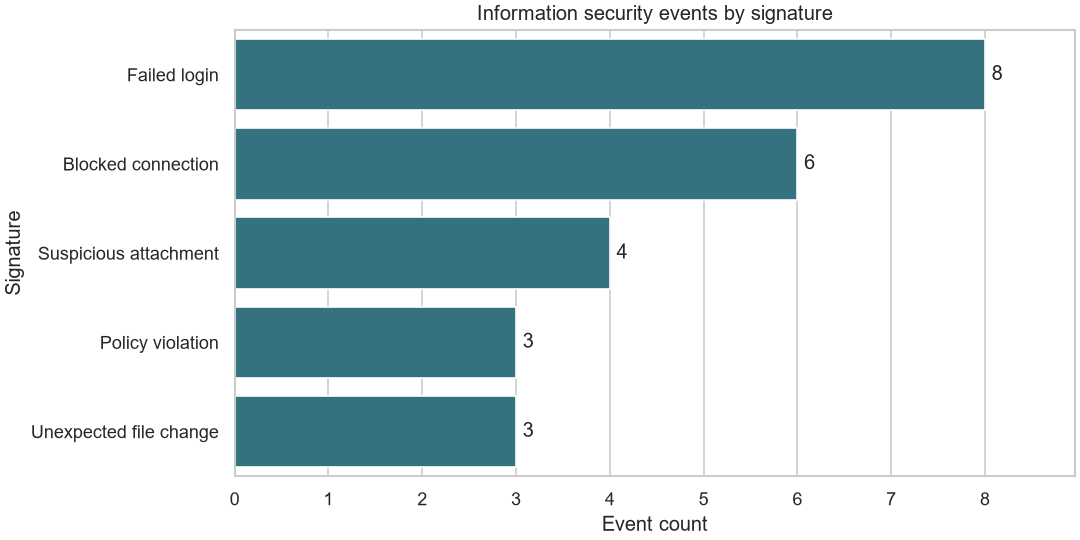

In [3]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
sns.barplot(data=distribution, x="count", y="signature", color="#287a8c", ax=ax)
ax.bar_label(ax.containers[0], padding=4)
ax.set_xlim(0, counts.max() * 1.12)
ax.set(
    title="Information security events by signature",
    xlabel="Event count",
    ylabel="Signature",
)
plt.show()

## Вывод

В наборе 24 события пяти типов. Чаще всего встречались неудачные попытки входа (`Failed login`) — 8 случаев, или 33,3 %. Реже всего встречались нарушения политики (`Policy violation`) и неожиданные изменения файлов (`Unexpected file change`) — по 3 случая, или 12,5 % каждый. Эти доли описывают учебный набор.